# Breaking the Black Box: Matrix Decompositions vs. NumPy/SciPy
**OKULTRA's Blackbox Warriors** · Raymond Morrow & Alan Valencia · MATH300, fall 2026

We're writing Householder QR and LU with partial pivoting ourselves and checking them against `numpy.linalg.qr` and `scipy.linalg.lu`. The bonus part is classical vs. modified Gram–Schmidt (Ray) and why pivoting matters (Alan).

**AI disclosure:** We used Claude (Anthropic) to explain any errors we had in this notebook and explain possible fixes. There is no AI-Generated code, everything has been handmade with plenty of sleepless nights and caffine induced cells.

**What's where**

| Section | What it does | Who |
|---|---|---|
| 1. Setup | imports, print settings, random seed | both |
| 2. Test matrices | exam matrices, Hilbert, random, tiny pivot, Wilkinson | Alan |
| 3. Metrics | reconstruction error, ‖QᵀQ − I‖, forward error, κ, growth factor | Ray |
| 4. Library baselines | NumPy QR and SciPy LU, converted to our conventions | both |
| 5. Exam hand checks | library output vs. our Exam 2 answers | both |
| 6. Our methods | stubs: Householder, CGS, MGS (Ray), LU with/without pivoting (Alan) | split |
| 7. Validation | runs every method on every test matrix | both |
| 8. Experiments | plots for the report and poster | split |

Just do Runtime → Run all. Right now Sections 7 and 8 only have the library versions in them. Once one of our stubs is filled in, it shows up in the tables and plots on its own.

## 1. Setup

In [ ]:
import time
from pathlib import Path

import numpy as np
import scipy
import scipy.linalg as sla
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=110)
RNG = np.random.default_rng(300)   # seed = course number, so we get the same random matrices every run
EPS = np.finfo(float).eps          # ~2.2e-16

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# uncomment to save figures to Drive (Colab deletes local files when the session ends)
# from google.colab import drive
# drive.mount("/content/drive")
# FIG_DIR = Path("/content/drive/MyDrive/blackbox-warriors/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

print("numpy", np.__version__, "| scipy", scipy.__version__, "| eps =", EPS)

numpy 2.4.6 | scipy 1.16.3 | eps = 2.220446049250313e-16


### Conventions (agreed on week 1)

- Everything is float64, and no function changes its input (copy first).
- QR means the *reduced* version: A is m×n with m ≥ n, Q is m×n with orthonormal columns, R is n×n upper triangular.
- Q and R are only unique up to signs, so before comparing entries we flip signs to make diag(R) positive. Otherwise we just compare ‖A − QR‖.
- LU returns `P, L, U` with PA = LU, where P is a permutation matrix and L has 1s on the diagonal.
- Watch out: `scipy.linalg.lu` gives A = P L U instead, so our P is SciPy's P transposed. Easy to mix up.

## 2. Test matrices

In [ ]:
def exam_qr_matrix():
    # exam 2 Q3. first column is [3, 4, 0] so its norm is 5, nice for doing it by hand
    return np.array([[3., 5.], [4., 12.], [0., 13.]])

def exam_lu_matrix():
    # exam 2 Q2. the (1,1) entry is 0 so A = LU doesn't exist unless you pivot
    return np.array([[0., 1., 3.], [2., 3., 1.], [6., 9., 8.]])

def hilbert(n):
    # H[i,j] = 1/(i+j+1) with 0-based i, j. gets ill-conditioned fast, cond ~ e^(3.5n)
    i, j = np.indices((n, n))
    return 1.0 / (i + j + 1)

def random_matrix(m, n=None, rng=RNG):
    # gaussian entries, almost always well conditioned. square if n isn't given
    if n is None:
        n = m
    return rng.standard_normal((m, n))

def tiny_pivot(eps=1e-20):
    # [[eps, 1], [1, 1]]. no pivoting = dividing by eps, which wrecks everything
    return np.array([[eps, 1.], [1., 1.]])

def wilkinson_growth(n):
    # 1 on the diagonal, -1 below it, last column all 1s.
    # partial pivoting never swaps here and the last column doubles every step, so growth = 2^(n-1)
    A = np.eye(n) - np.tril(np.ones((n, n)), -1)
    A[:, -1] = 1.0
    return A

print("exam QR matrix:\n", exam_qr_matrix())
print("\nexam LU matrix:\n", exam_lu_matrix())
print("\nwilkinson, n = 5:\n", wilkinson_growth(5))
print()
for n in (3, 6, 9, 12):
    print(f"cond(H_{n}) = {np.linalg.cond(hilbert(n)):.1e}")

exam QR matrix:
 [[ 3.  5.]
 [ 4. 12.]
 [ 0. 13.]]

exam LU matrix:
 [[0. 1. 3.]
 [2. 3. 1.]
 [6. 9. 8.]]

wilkinson, n = 5:
 [[ 1.  0.  0.  0.  1.]
 [-1.  1.  0.  0.  1.]
 [-1. -1.  1.  0.  1.]
 [-1. -1. -1.  1.  1.]
 [-1. -1. -1. -1.  1.]]

cond(H_3) = 5.2e+02
cond(H_6) = 1.5e+07
cond(H_9) = 4.9e+11
cond(H_12) = 1.8e+16


## 3. Metrics

In [ ]:
def rel_recon_qr(A, Q, R):
    # ||A - QR||_F / ||A||_F
    return np.linalg.norm(A - Q @ R) / np.linalg.norm(A)

def rel_recon_lu(A, P, L, U):
    # same idea for LU, but compare against PA
    return np.linalg.norm(P @ A - L @ U) / np.linalg.norm(A)

def orth_loss(Q):
    # how far Q is from having orthonormal columns (0 = perfect)
    I = np.eye(Q.shape[1])
    return np.linalg.norm(Q.T @ Q - I, 2)

def forward_error(x_hat, x_true):
    return np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)

def cond2(A):
    return np.linalg.cond(A, 2)   # sigma_max / sigma_min

def growth_factor(A, U):
    # largest entry of U relative to the largest entry of A
    return np.abs(U).max() / np.abs(A).max()

def normalize_qr(Q, R):
    # QR is only unique up to signs, so flip columns of Q and rows of R until diag(R) > 0.
    # np.sign(0) is 0, so set those to +1 or we'd zero out a column
    signs = np.sign(np.diag(R)).copy()
    signs[signs == 0] = 1.0
    return Q * signs, R * signs[:, None]

## 4. Library baselines

In [ ]:
def numpy_qr(A):
    # numpy calls LAPACK (dgeqrf + dorgqr), so this is Householder under the hood
    return np.linalg.qr(A, mode="reduced")

def scipy_lu(A):
    # LAPACK dgetrf with partial pivoting. scipy gives A = P_s L U and we want PA = LU, so P = P_s^T
    P_s, L, U = sla.lu(A)
    return P_s.T, L, U

## 5. Checking our Exam 2 hand answers

If NumPy and SciPy agree with what we got by hand on the exam, our hand answers are right and we can reuse them as tests for our own code in Section 7. If none of the asserts fail, everything matched.

In [ ]:
# Q3: QR of [3 5; 4 12; 0 13]
A = exam_qr_matrix()
r22 = np.sqrt(179.24)    # ~13.388, it's ||a2 - 12.6 q1|| from the exam
Q_hand = np.array([[0.6, -2.56 / r22],
                   [0.8,  1.92 / r22],
                   [0.0, 13.00 / r22]])
R_hand = np.array([[5.0, 12.6],
                   [0.0, r22]])

Q_raw, R_raw = numpy_qr(A)
print("numpy R as returned (Householder signs):\n", R_raw)
Q_np, R_np = normalize_qr(Q_raw, R_raw)
print("\nnumpy R after flipping signs:\n", R_np)
print("\nnumpy Q after flipping signs:\n", Q_np)
assert np.allclose(Q_np, Q_hand) and np.allclose(R_np, R_hand)
print("\nQ3 matches our hand answer")

# Q3(b): Householder reflector for x = [3, 4, 0] by hand
x = A[:, 0]
v = x.copy()
v[0] += np.sign(x[0]) * np.linalg.norm(x)   # v = x + sign(x1)||x|| e1 = [8, 4, 0]
H = np.eye(3) - 2 * np.outer(v, v) / (v @ v)
print("\nv =", v)
print("H =\n", H)
print("Hx =", H @ x)
assert np.allclose(H @ x, [-5, 0, 0])
assert np.isclose(np.linalg.norm(H @ x), np.linalg.norm(x))   # reflections don't change the length
print("H sends x to -||x|| e1 and keeps the norm")

numpy R as returned (Householder signs):
 [[ -5.     -12.6   ]
 [  0.     -13.3881]]

numpy R after flipping signs:
 [[ 5.     12.6   ]
 [-0.     13.3881]]

numpy Q after flipping signs:
 [[ 0.6    -0.1912]
 [ 0.8     0.1434]
 [ 0.      0.971 ]]

Q3 matches our hand answer

v = [8. 4. 0.]
H =
 [[-0.6 -0.8  0. ]
 [-0.8  0.6  0. ]
 [ 0.   0.   1. ]]
Hx = [-5. -0.  0.]
H sends x to -||x|| e1 and keeps the norm


In [ ]:
# Q2: PA = LU of [0 1 3; 2 3 1; 6 9 8]
A = exam_lu_matrix()
P_hand = np.array([[0., 0., 1.],
                   [1., 0., 0.],
                   [0., 1., 0.]])    # rows of A in the order 3, 1, 2 (two swaps)
L_hand = np.array([[1., 0., 0.],
                   [0., 1., 0.],
                   [1/3, 0., 1.]])
U_hand = np.array([[6., 9., 8.],
                   [0., 1., 3.],
                   [0., 0., -5/3]])

P, L, U = scipy_lu(A)
print("P =\n", P)
print("L =\n", L)
print("U =\n", U)
assert np.allclose(P, P_hand) and np.allclose(L, L_hand) and np.allclose(U, U_hand)
assert np.allclose(P @ A, L @ U)
print("\nQ2 matches our hand answer")
# the 2nd swap is needed because after step 1 the (2,2) entry is 0
print("cond(P) =", cond2(P))
print("cond(PA) == cond(A)?", np.isclose(cond2(P @ A), cond2(A)))

P =
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]
L =
 [[1.     0.     0.    ]
 [0.     1.     0.    ]
 [0.3333 0.     1.    ]]
U =
 [[ 6.      9.      8.    ]
 [ 0.      1.      3.    ]
 [ 0.      0.     -1.6667]]

Q2 matches our hand answer
cond(P) = 1.0
cond(PA) == cond(A)? True


## 6. Our methods

Everything below is still a stub. Delete the `raise NotImplementedError` and write the algorithm (the comments follow Trefethen & Bau). Section 7 starts testing a method as soon as its stub is gone.

### 6a. Householder QR, CGS, MGS (Ray)

In [ ]:
def householder_qr(A):
    # reduced QR with Householder reflections (T&B alg 10.1, then 10.3 to build Q)
    # returns Q (m x n) and R (n x n) with A = QR
    #
    # plan:
    #   R = copy of A, keep a list of the v's
    #   for k = 0..n-1:
    #       x = R[k:, k]
    #       v = x, then v[0] += sign(x[0]) * ||x||    (use +1 if x[0] == 0. adding avoids cancellation)
    #       normalize v and save it
    #       R[k:, k:] -= 2 v (v^T R[k:, k:])           # apply the reflector directly, never build H
    #   Q = apply the saved reflectors in reverse to the first n columns of I
    #   return Q, triu(R[:n, :])
    A = np.array(A, dtype=float)   # copy so we don't touch the input
    m, n = A.shape
    raise NotImplementedError


def cgs(A):
    # classical Gram-Schmidt (T&B alg 7.1)
    #   for j = 0..n-1:
    #       v = A[:, j]
    #       for i < j: R[i, j] = Q[:, i] . A[:, j]    <- dot with the ORIGINAL column
    #                  v -= R[i, j] Q[:, i]
    #       R[j, j] = ||v||,  Q[:, j] = v / R[j, j]
    A = np.array(A, dtype=float)
    m, n = A.shape
    raise NotImplementedError


def mgs(A):
    # modified Gram-Schmidt (T&B alg 8.1). same as cgs in exact arithmetic, just reordered
    #   V = copy of A
    #   for i = 0..n-1:
    #       R[i, i] = ||V[:, i]||,  Q[:, i] = V[:, i] / R[i, i]
    #       for j > i: R[i, j] = Q[:, i] . V[:, j]    <- dot with the UPDATED column (this is the only difference)
    #                  V[:, j] -= R[i, j] Q[:, i]
    A = np.array(A, dtype=float)
    m, n = A.shape
    raise NotImplementedError

### 6b. LU with and without pivoting (Alan)

In [ ]:
def lu_partial_pivot(A):
    # PA = LU with partial pivoting (T&B alg 21.1)
    #   U = copy of A, L = I, P = I
    #   for k = 0..n-2:
    #       find the row i >= k with the biggest |U[i, k]|
    #       swap rows k and i in U[:, k:], L[:, :k], and P
    #       for j > k: L[j, k] = U[j, k] / U[k, k]
    #                  U[j, k:] -= L[j, k] * U[k, k:]
    #   return P, L, U
    A = np.array(A, dtype=float)
    n = A.shape[0]
    raise NotImplementedError


def lu_no_pivot(A):
    # A = LU with no pivoting (T&B alg 20.1). this is the one that falls apart on tiny pivots, see 8.2
    #   U = copy of A, L = I
    #   for k = 0..n-2:
    #       for j > k: L[j, k] = U[j, k] / U[k, k]
    #                  U[j, k:] -= L[j, k] * U[k, k:]
    #   return L, U
    A = np.array(A, dtype=float)
    n = A.shape[0]
    raise NotImplementedError

## 7. Validation against the library

Every method runs on the same test matrices. "not implemented yet" just means that stub is still there. A method passes if its reconstruction error is under 1e-12 and, for QR, its sign-flipped R matches NumPy's. We skip the R comparison on Hilbert since it's too ill-conditioned for entry-by-entry comparison to mean much.

On `hilbert 8`, expect CGS to show a big ‖QᵀQ − I‖ and MGS a smaller one. That's not a bug, it's what the bonus experiment in 8.1 is about.

In [ ]:
QR_METHODS = {"numpy": numpy_qr, "householder": householder_qr, "cgs": cgs, "mgs": mgs}
LU_METHODS = {"scipy": scipy_lu, "lu_partial_pivot": lu_partial_pivot}

def try_run(fn, A):
    # None means fn is still a stub, so the tables and plots can skip it
    try:
        return fn(A)
    except NotImplementedError:
        return None

def implemented(methods):
    # only keep the methods that actually run (quick test on a 3x3 identity)
    done = {}
    for name, fn in methods.items():
        if try_run(fn, np.eye(3)) is not None:
            done[name] = fn
    return done

QR_TESTS = {
    "exam Q3 (3x2)": exam_qr_matrix(),
    "random 6x6": random_matrix(6),
    "random 50x30": random_matrix(50, 30),
    "hilbert 8": hilbert(8),
}
LU_TESTS = {
    "exam Q2 (3x3)": exam_lu_matrix(),
    "random 6x6": random_matrix(6),
    "random 100x100": random_matrix(100),
    "hilbert 8": hilbert(8),
}

def validate_qr():
    print(f"{'method':<13}{'matrix':<16}{'recon':>10}{'||QtQ-I||':>12}{'R vs numpy':>12}  result")
    for name, fn in QR_METHODS.items():
        for label, A in QR_TESTS.items():
            out = try_run(fn, A)
            if out is None:
                print(f"{name:<13}{label:<16}  not implemented yet")
                break
            Q, R = normalize_qr(*out)
            _, R_ref = normalize_qr(*numpy_qr(A))
            rec = rel_recon_qr(A, Q, R)
            orth = orth_loss(Q)
            dR = np.linalg.norm(R - R_ref) / np.linalg.norm(R_ref)
            # don't compare R on hilbert, it's too ill-conditioned
            passed = rec < 1e-12 and ("hilbert" in label or dR < 1e-10)
            print(f"{name:<13}{label:<16}{rec:>10.1e}{orth:>12.1e}{dR:>12.1e}  {'pass' if passed else 'CHECK'}")

def validate_lu():
    print(f"{'method':<18}{'matrix':<16}{'recon':>10}{'P vs scipy':>12}{'growth':>9}  result")
    for name, fn in LU_METHODS.items():
        for label, A in LU_TESTS.items():
            out = try_run(fn, A)
            if out is None:
                print(f"{name:<18}{label:<16}  not implemented yet")
                break
            P, L, U = out
            P_ref = scipy_lu(A)[0]
            rec = rel_recon_lu(A, P, L, U)
            same_P = np.array_equal(P, P_ref)
            # L should be unit lower triangular and U upper triangular
            shapes_ok = np.allclose(np.diag(L), 1) and np.allclose(L, np.tril(L)) and np.allclose(U, np.triu(U))
            passed = rec < 1e-12 and shapes_ok
            print(f"{name:<18}{label:<16}{rec:>10.1e}{str(same_P):>12}{growth_factor(A, U):>9.2f}  {'pass' if passed else 'CHECK'}")

validate_qr()
print()
validate_lu()

method       matrix               recon   ||QtQ-I||  R vs numpy  result
numpy        exam Q3 (3x2)      1.9e-16     4.5e-16     0.0e+00  pass
numpy        random 6x6         4.8e-16     7.1e-16     0.0e+00  pass
numpy        random 50x30       4.1e-16     1.0e-15     0.0e+00  pass
numpy        hilbert 8          1.7e-16     8.0e-16     0.0e+00  pass
householder  exam Q3 (3x2)     not implemented yet
cgs          exam Q3 (3x2)     not implemented yet
mgs          exam Q3 (3x2)     not implemented yet

method            matrix               recon  P vs scipy   growth  result
scipy             exam Q2 (3x3)      0.0e+00        True     1.00  pass
scipy             random 6x6         8.5e-17        True     1.06  pass
scipy             random 100x100     4.9e-16        True     4.94  pass
scipy             hilbert 8          3.1e-17        True     1.00  pass
lu_partial_pivot  exam Q2 (3x3)     not implemented yet


In [ ]:
# our methods vs. the exact exam answers (anything still a stub gets skipped)
for name, fn in implemented({"householder": householder_qr, "cgs": cgs, "mgs": mgs}).items():
    Q, R = normalize_qr(*fn(exam_qr_matrix()))
    assert np.allclose(Q, Q_hand) and np.allclose(R, R_hand), name
    print(name, "matches exam 2 Q3")
if implemented({"lu": lu_partial_pivot}):
    P, L, U = lu_partial_pivot(exam_lu_matrix())
    assert np.allclose(P, P_hand) and np.allclose(L, L_hand) and np.allclose(U, U_hand)
    print("lu_partial_pivot matches exam 2 Q2")
print("exam checks done")

exam checks done


## 8. Experiments

Each cell saves its plot to `figures/` so we can use it in the report and poster. Our methods get added to the plots once they're implemented.

### 8.1 Loss of orthogonality on Hilbert matrices (Ray's bonus)
What we expect: Householder stays around ε, MGS grows like κε, and CGS grows like κ²ε until it tops out around 1.

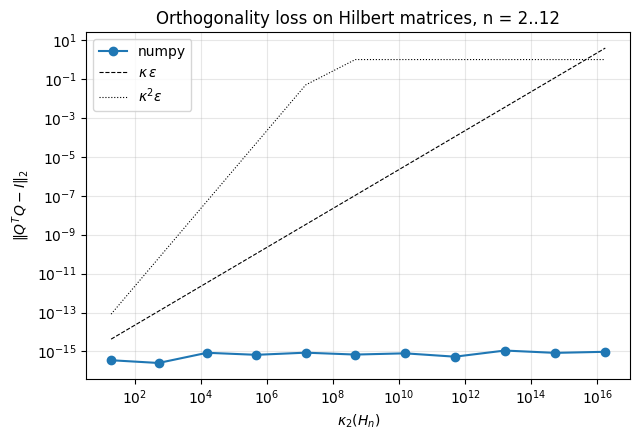

In [ ]:
ns = list(range(2, 13))
kappas = [cond2(hilbert(n)) for n in ns]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, fn in implemented(QR_METHODS).items():
    losses = [orth_loss(fn(hilbert(n))[0]) for n in ns]
    ax.loglog(kappas, losses, "o-", label=name)
# the two lines theory predicts (MGS ~ k*eps, CGS ~ k^2*eps capped at 1)
k = np.array(kappas)
ax.loglog(k, k * EPS, "k--", lw=0.8, label=r"$\kappa\,\varepsilon$")
ax.loglog(k, np.minimum(k**2 * EPS, 1), "k:", lw=0.8, label=r"$\kappa^2\varepsilon$")
ax.set(xlabel=r"$\kappa_2(H_n)$", ylabel=r"$\|Q^TQ - I\|_2$", title="Orthogonality loss on Hilbert matrices, n = 2..12")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "orthogonality_hilbert.pdf"); plt.show()

### 8.2 Why pivoting matters: the tiny pivot matrix (Alan's bonus)
Solve Ax = b with A = [[ε, 1], [1, 1]]. The exact answer is basically [1, 1] and the matrix itself is well conditioned, so any big error here is the algorithm's fault.

In [ ]:
def solve_lu(P, L, U, b):
    # forward sub with L (unit diagonal), then back sub with U
    y = sla.solve_triangular(L, P @ b, lower=True, unit_diagonal=True)
    return sla.solve_triangular(U, y)

b = np.array([1.0, 2.0])
for e in (1e-4, 1e-10, 1e-20):
    A = tiny_pivot(e)
    x_true = np.array([1 / (1 - e), (1 - 2*e) / (1 - e)])   # solved by hand for b = [1, 2]
    line = f"eps = {e:.0e}:  partial pivoting err = {forward_error(solve_lu(*scipy_lu(A), b), x_true):.1e}"
    out = try_run(lu_no_pivot, A)
    if out is None:
        line += "   no pivoting: not implemented yet"
    else:
        L, U = out
        line += f"   no pivoting err = {forward_error(solve_lu(np.eye(2), L, U, b), x_true):.1e}   max|U| = {np.abs(U).max():.1e}"
    print(line)

eps = 1e-04:  partial pivoting err = 1.6e-16   no pivoting: not implemented yet
eps = 1e-10:  partial pivoting err = 0.0e+00   no pivoting: not implemented yet
eps = 1e-20:  partial pivoting err = 0.0e+00   no pivoting: not implemented yet


### 8.3 Growth factor on the Wilkinson matrix
Partial pivoting is backward stable in practice, but this matrix hits the worst-case growth of 2ⁿ⁻¹. Random matrices are on the plot for comparison.

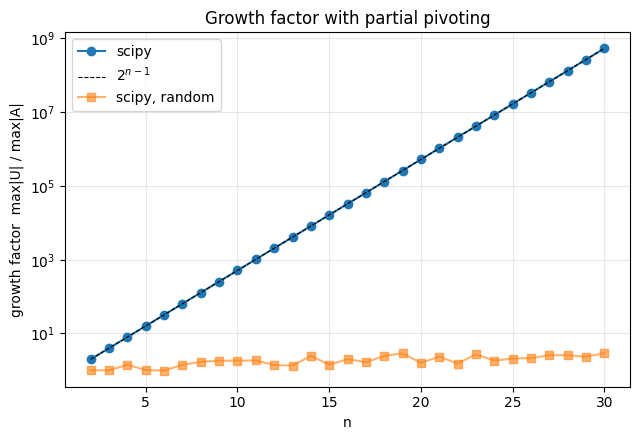

In [ ]:
ns = list(range(2, 31))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, fn in implemented(LU_METHODS).items():
    g = []
    for n in ns:
        W = wilkinson_growth(n)
        g.append(growth_factor(W, fn(W)[2]))
    ax.semilogy(ns, g, "o-", label=name)
ax.semilogy(ns, [2.0 ** (n - 1) for n in ns], "k--", lw=0.8, label=r"$2^{n-1}$")

# random matrices for comparison. make B once so A and U come from the same matrix
g_rand = []
for n in ns:
    B = random_matrix(n)
    g_rand.append(growth_factor(B, scipy_lu(B)[2]))
ax.semilogy(ns, g_rand, "s-", alpha=0.6, label="scipy, random")

ax.set(xlabel="n", ylabel="growth factor  max|U| / max|A|", title="Growth factor with partial pivoting")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "growth_wilkinson.pdf"); plt.show()

### 8.4 Forward error vs. κε on Hilbert systems
Solve Hₙx = b where the true x is all ones. The backward error stays tiny the whole time, but the forward error follows κ(A)·ε. Same "poorly conditioned" idea as Exam 2 Q1.

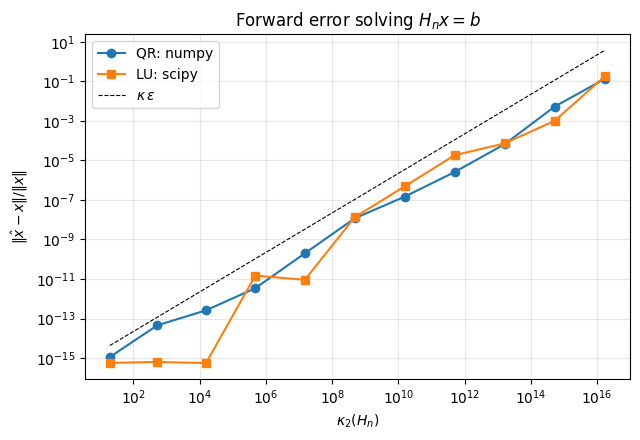

In [ ]:
def solve_qr(Q, R, b):
    # Rx = Q^T b
    return sla.solve_triangular(R, Q.T @ b)

# b = H @ ones so we know the exact answer is all ones
ns = list(range(2, 13))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
kap = np.array([cond2(hilbert(n)) for n in ns])
for name, fn in implemented(QR_METHODS).items():
    errs = [forward_error(solve_qr(*fn(hilbert(n)), hilbert(n) @ np.ones(n)), np.ones(n)) for n in ns]
    ax.loglog(kap, errs, "o-", label=f"QR: {name}")
for name, fn in implemented(LU_METHODS).items():
    errs = [forward_error(solve_lu(*fn(hilbert(n)), hilbert(n) @ np.ones(n)), np.ones(n)) for n in ns]
    ax.loglog(kap, errs, "s-", label=f"LU: {name}")
ax.loglog(kap, kap * EPS, "k--", lw=0.8, label=r"$\kappa\,\varepsilon$")
ax.set(xlabel=r"$\kappa_2(H_n)$", ylabel=r"$\|\hat x - x\| / \|x\|$", title="Forward error solving $H_n x = b$")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "forward_error_hilbert.pdf"); plt.show()

### 8.5 Timing vs. n (bonus)
The library versions are compiled LAPACK and ours are Python loops, so ours will be a lot slower. What we actually care about is the slope, since both should be O(n³).

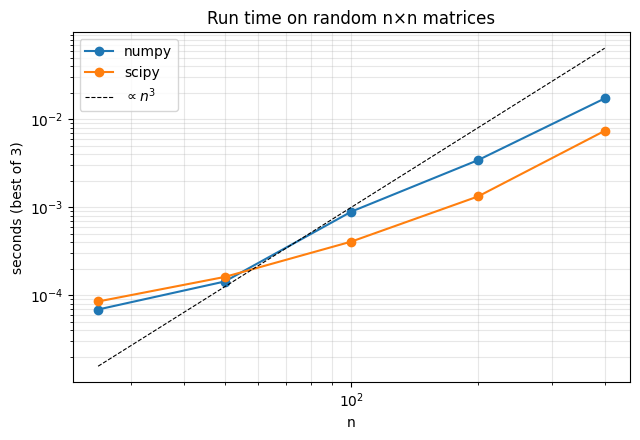

In [ ]:
def best_time(fn, A, reps=3):
    # best of 3 so a random slow run doesn't mess up the plot
    best = None
    for _ in range(reps):
        t0 = time.perf_counter()
        fn(A)
        t = time.perf_counter() - t0
        if best is None or t < best:
            best = t
    return best

sizes = [25, 50, 100, 200, 400]
methods = {**implemented(QR_METHODS), **implemented(LU_METHODS)}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, fn in methods.items():
    ax.loglog(sizes, [best_time(fn, random_matrix(n)) for n in sizes], "o-", label=name)
s = np.array(sizes, dtype=float)
ax.loglog(s, 1e-9 * s**3, "k--", lw=0.8, label=r"$\propto n^3$")   # reference slope only, the constant is arbitrary
ax.set(xlabel="n", ylabel="seconds (best of 3)", title="Run time on random n×n matrices")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "timing.pdf"); plt.show()